### Kelompok 5 : Toni Perkasa Darmawan
#### 252310062 | TI-23-KA
##### Tugas Machine Learning Week 6

##### Klasifikasi: **Support Vector Classifier**
* kernel = 'rbf'
* C = 1.5
* gamma = 'scale'
* random_state = 100
##### Clustering: **Kmeans**
* n_clusters = 4
* init = 'k-means++'
* n_init = 25
* max_iter = 400
* random_state = 100

In [1]:
import pandas as pd
import numpy as np

# Read Dataset
df = pd.read_csv('heart_modified.csv')

# Print Dataset 1
print(f"Bentuk data (baris, kolom): {df.shape}\n")
df.head()

Bentuk data (baris, kolom): (918, 12)



,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140.0,289.0,0,Normal,172.0,N,0.0,Up,0
1,49,F,NAP,160.0,NaN,0,Normal,156.0,N,1.0,Flat,1
2,37,M,ATA,130.0,283.0,0,ST,98.0,N,0.0,Up,0
3,48,F,ASY,138.0,214.0,0,Normal,108.0,Y,1.5,Flat,1
4,54,M,NAP,150.0,195.0,0,Normal,122.0,N,0.0,Up,0


#### 1. Menghitung jumlah nilai unik per kolom

In [2]:
# 1. Menghitung jumlah nilai unik per kolom
print("=== JUMLAH NILAI UNIK SETIAP ATRIBUT ===")
print(df.nunique())

print("\n=== DAFTAR NILAI UNIK UNTUK ATRIBUT KATEGORIK ===")
# Menentukan atribut kategorik (termasuk tipe 'object' dan biner FastingBS)
kategorik_cols = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

for col in kategorik_cols:
    unique_vals = df[col].dropna().unique().tolist()
    print(f"- {col:15}: {unique_vals}")

=== JUMLAH NILAI UNIK SETIAP ATRIBUT ===
Age                50
Sex                 2
ChestPainType       4
RestingBP          67
Cholesterol       219
FastingBS           2
RestingECG          3
MaxHR             119
ExerciseAngina      2
Oldpeak            53
ST_Slope            3
HeartDisease        2
dtype: int64

=== DAFTAR NILAI UNIK UNTUK ATRIBUT KATEGORIK ===
- Sex            : ['M', 'F']
- ChestPainType  : ['ATA', 'NAP', 'ASY', 'TA']
- FastingBS      : [0, 1]
- RestingECG     : ['Normal', 'ST', 'LVH']
- ExerciseAngina : ['N', 'Y']
- ST_Slope       : ['Up', 'Flat', 'Down']


In [3]:
# Ringkasan identifikasi seluruh atribut untuk laporan
atribut_info = pd.DataFrame({
    'Nama Atribut': df.columns,
    'Peran': ['Label' if col == 'HeartDisease' else 'Prediktor' for col in df.columns],
    'Tipe Data': ['Numerik Kontinu' if col in ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
                  else 'Kategorik Biner' if col in ['Sex', 'FastingBS', 'ExerciseAngina', 'HeartDisease']
                  else 'Kategorik Nominal' for col in df.columns],
    'Jumlah Nilai Unik': df.nunique().values
})
atribut_info

,Nama Atribut,Peran,Tipe Data,Jumlah Nilai Unik
0,Age,Prediktor,Numerik Kontinu,50
1,Sex,Prediktor,Kategorik Biner,2
2,ChestPainType,Prediktor,Kategorik Nominal,4
3,RestingBP,Prediktor,Numerik Kontinu,67
4,Cholesterol,Prediktor,Numerik Kontinu,219
5,FastingBS,Prediktor,Kategorik Biner,2
6,RestingECG,Prediktor,Kategorik Nominal,3
7,MaxHR,Prediktor,Numerik Kontinu,119
8,ExerciseAngina,Prediktor,Kategorik Biner,2
9,Oldpeak,Prediktor,Numerik Kontinu,53


### 2. Data Pre-Processing

#### a. Memisahkan atribut prediktor (X) dan label (y)

In [4]:
# 2a. Memisahkan atribut prediktor (X) dan label (y)
X = df.drop(columns=['HeartDisease'])
y = df['HeartDisease']

print("Dimensi X (prediktor):", X.shape)
print("Dimensi y (label)    :", y.shape)

# Cek kolom yang memiliki missing values
print("\n=== JUMLAH MISSING VALUES SEBELUM PRAPROSES ===")
print(X.isna().sum()[X.isna().sum() > 0])

# 2e. Statistik deskriptif SEBELUM praproses
print("\n=== STATISTIK DESKRIPTIF SEBELUM PRAPROSES ===")
X.describe()

Dimensi X (prediktor): (918, 11)
Dimensi y (label)    : (918,)

=== JUMLAH MISSING VALUES SEBELUM PRAPROSES ===
RestingBP      18
Cholesterol    18
MaxHR          18
dtype: int64

=== STATISTIK DESKRIPTIF SEBELUM PRAPROSES ===


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak
count,918.000000,900.000000,900.000000,918.000000,900.000000,918.000000
mean,53.510893,132.411111,199.252222,0.233115,136.874444,0.887364
std,9.432617,18.611534,109.644221,0.423046,25.557038,1.066570
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000
25%,47.000000,120.000000,173.750000,0.000000,120.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000
75%,60.000000,140.000000,267.250000,0.000000,156.000000,1.500000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000


#### b. Imputasi Missing Values dengan _SimpleImputer_

In [5]:
from sklearn.impute import SimpleImputer

# Daftar kolom numerik
kolom_numerik = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

# 2b. SimpleImputer dengan strategi 'mean'
imputer = SimpleImputer(strategy='mean')
X[kolom_numerik] = imputer.fit_transform(X[kolom_numerik])

# Verifikasi: memastikan sudah tidak ada missing values
print("Sisa missing values setelah SimpleImputer:")
print(X[kolom_numerik].isna().sum())

Sisa missing values setelah SimpleImputer:
Age            0
RestingBP      0
Cholesterol    0
MaxHR          0
Oldpeak        0
dtype: int64


#### d. Praproses tambahan: One-Hot Encoding untuk atribut kategorik

In [6]:
# 2d. Praproses tambahan: One-Hot Encoding untuk atribut kategorik
kolom_kategorik = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

# Mengubah kategori menjadi representasi numerik biner (0/1)
X_encoded = pd.get_dummies(X, columns=kolom_kategorik, drop_first=True, dtype=int)

print("Bentuk dataset setelah One-Hot Encoding:", X_encoded.shape)
X_encoded.head()

Bentuk dataset setelah One-Hot Encoding: (918, 15)


,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,FastingBS_1,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40.0,140.0,289.000000,172.0,0.0,1,1,0,0,0,1,0,0,0,1
1,49.0,160.0,199.252222,156.0,1.0,0,0,1,0,0,1,0,0,1,0
2,37.0,130.0,283.000000,98.0,0.0,1,1,0,0,0,0,1,0,0,1
3,48.0,138.0,214.000000,108.0,1.5,0,0,0,0,0,1,0,1,1,0
4,54.0,150.0,195.000000,122.0,0.0,1,0,1,0,0,1,0,0,0,1


#### c. Menerapkan StandardScaler untuk mengubah nilai atribut prediktor berjenis numerik

In [7]:
from sklearn.preprocessing import StandardScaler

# 2c. Menerapkan StandardScaler pada fitur numerik
scaler = StandardScaler()
X_clean = X_encoded.copy()
X_clean[kolom_numerik] = scaler.fit_transform(X_clean[kolom_numerik])

print("Praproses selesai! Fitur siap digunakan untuk pemodelan.")
X_clean.head()

Praproses selesai! Fitur siap digunakan untuk pemodelan.


,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,FastingBS_1,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,-1.433140,0.412038,0.827141,1.388846,-0.832432,1,1,0,0,0,1,0,0,0,1
1,-0.478484,1.497937,0.000000,0.756215,0.105664,0,0,1,0,0,1,0,0,1,0
2,-1.751359,-0.130911,0.771843,-1.537075,-0.832432,1,1,0,0,0,0,1,0,0,1
3,-0.584556,0.303448,0.135920,-1.141681,0.574711,0,0,0,0,0,1,0,1,1,0
4,0.051881,0.954988,-0.039190,-0.588128,-0.832432,1,0,1,0,0,1,0,0,0,1


#### e. Menampilkan statistik deskriptif dari atribut data sebelum dan setelah dilakukan praproses data

In [8]:
# 2e. Statistik deskriptif SETELAH praproses
print("=== STATISTIK DESKRIPTIF SETELAH PRAPROSES ===")
X_clean.describe()

=== STATISTIK DESKRIPTIF SETELAH PRAPROSES ===


,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,FastingBS_1,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
count,9.180000e+02,9.180000e+02,9.180000e+02,9.180000e+02,9.180000e+02,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,-1.083616e-16,7.275710e-16,-3.096047e-17,-7.894919e-16,1.238419e-16,0.789760,0.188453,0.221133,0.050109,0.233115,0.601307,0.193900,0.404139,0.501089,0.430283
std,1.000545e+00,1.000545e+00,1.000545e+00,1.000545e+00,1.000545e+00,0.407701,0.391287,0.415236,0.218289,0.423046,0.489896,0.395567,0.490992,0.500271,0.495386
min,-2.706015e+00,-7.189253e+00,-1.836365e+00,-3.039576e+00,-3.271482e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-6.906294e-01,-6.738605e-01,-2.189072e-01,-6.672068e-01,-8.324324e-01,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,5.188098e-02,-1.309111e-01,2.096499e-01,2.473414e-02,-2.695748e-01,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,6.883185e-01,4.120382e-01,6.220785e-01,7.166751e-01,5.747115e-01,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000
max,2.491558e+00,3.669734e+00,3.721053e+00,2.575031e+00,4.983762e+00,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


### 3. Membangun model klasifikasi berdasarkan dataset yang telah dilakukan praproses data

#### b. Metode holdout: 85% training dan 15% testing

In [11]:
from sklearn.model_selection import train_test_split

# 3b. Metode holdout: 85% training dan 15% testing
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, 
    y, 
    test_size=0.15, 
    random_state=100, 
    stratify=y
)

print(f"Jumlah data training : {X_train.shape[0]} sampel (85%)")
print(f"Jumlah data testing  : {X_test.shape[0]} sampel (15%)")

Jumlah data training : 780 sampel (85%)
Jumlah data testing  : 138 sampel (15%)


#### 3a. Membangun model Support Vector Machine (SVC)

In [12]:
from sklearn.svm import SVC

# 3a. Membangun model Support Vector Machine (SVC)
svm_model = SVC(
    kernel='rbf', 
    C=1.5, 
    gamma='scale', 
    random_state=100
)

# Melatih model dengan data training
svm_model.fit(X_train, y_train)
print("Model SVM berhasil dilatih!")

Model SVM berhasil dilatih!


#### 3c. Menghitung Akurasi

In [13]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Melakukan prediksi pada data testing
y_pred = svm_model.predict(X_test)

# 3c. Menghitung Akurasi
akurasi = accuracy_score(y_test, y_pred)
print(f"Akurasi Model SVM: {akurasi * 100:.2f}%\n")

# 3c. Menampilkan Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("=== CONFUSION MATRIX ===")
print(cm)
print()

# Evaluasi tambahan: Classification Report
print("=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, target_names=['Normal (0)', 'Heart Disease (1)']))

Akurasi Model SVM: 84.06%

=== CONFUSION MATRIX ===
[[54  8]
 [14 62]]

=== CLASSIFICATION REPORT ===
                   precision    recall  f1-score   support

       Normal (0)       0.79      0.87      0.83        62
Heart Disease (1)       0.89      0.82      0.85        76

         accuracy                           0.84       138
        macro avg       0.84      0.84      0.84       138
     weighted avg       0.84      0.84      0.84       138



##### Visualisasi Confusin Matrix

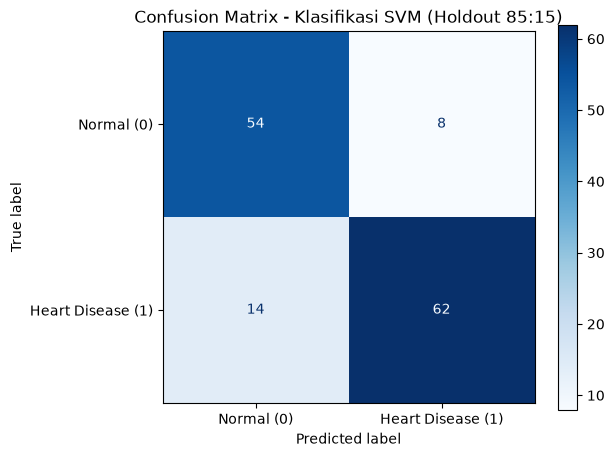

In [15]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal (0)', 'Heart Disease (1)'])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title("Confusion Matrix - Klasifikasi SVM (Holdout 85:15)")
plt.show()

### 4. Membangun model clustering berdasarkan dataset yang telah dilakukan praproses data

In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 4a. Membangun model K-Means dengan k=4
kmeans = KMeans(
    n_clusters=4, 
    init='k-means++', 
    n_init=25, 
    max_iter=400, 
    random_state=100
)

# Melatih model clustering pada X_clean
kmeans.fit(X_clean)

# Mendapatkan label cluster untuk setiap sampel data
cluster_labels = kmeans.labels_

# 4b. Menghitung SSE (Inertia) dan Silhouette Score
sse = kmeans.inertia_
sil_score = silhouette_score(X_clean, cluster_labels)

print("=== HASIL EVALUASI CLUSTERING K-MEANS (k=4) ===")
print(f"SSE (Sum of Squared Errors / Inertia) : {sse:.4f}")
print(f"Silhouette Score                      : {sil_score:.4f}\n")

# Menampilkan distribusi jumlah data di setiap cluster
print("Distribusi Anggota Tiap Cluster:")
distribusi = pd.Series(cluster_labels).value_counts().sort_index()
for cluster_id, count in distribusi.items():
    print(f"- Cluster {cluster_id}: {count} data ({count / len(X_clean) * 100:.1f}%)")

=== HASIL EVALUASI CLUSTERING K-MEANS (k=4) ===
SSE (Sum of Squared Errors / Inertia) : 4079.9247
Silhouette Score                      : 0.1458

Distribusi Anggota Tiap Cluster:
- Cluster 0: 249 data (27.1%)
- Cluster 1: 263 data (28.6%)
- Cluster 2: 239 data (26.0%)
- Cluster 3: 167 data (18.2%)


#### Perbandingan SSE & Silhouette Score untuk Berbagai Nilai 𝑘

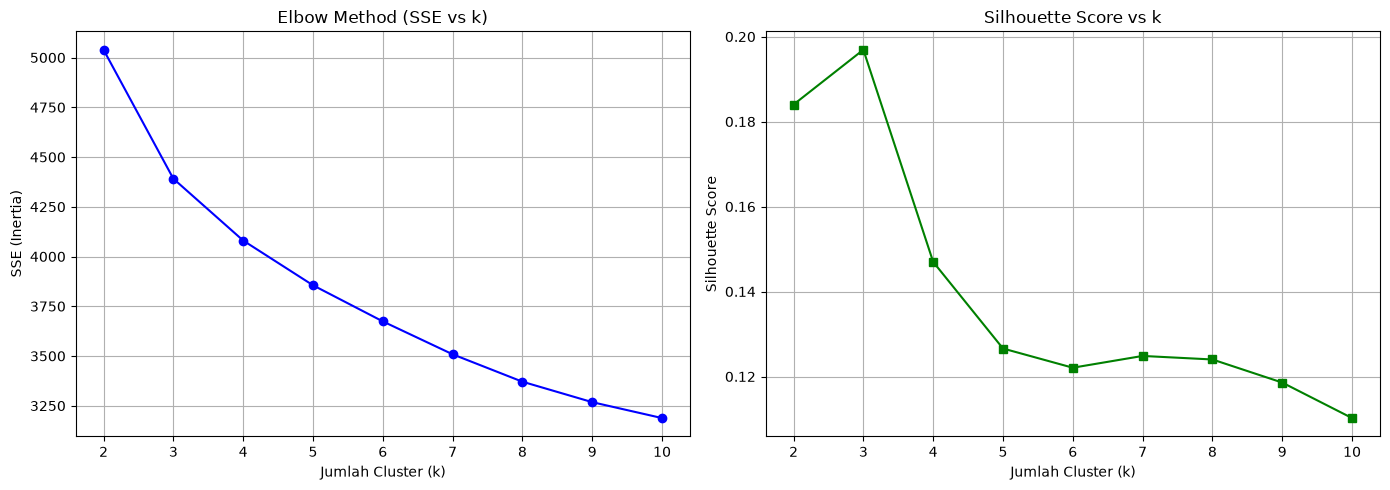

In [17]:
# Evaluasi clustering untuk berbagai nilai k (k = 2 hingga 10)
k_range = range(2, 11)
sse_list = []
sil_list = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, max_iter=300, random_state=100)
    km.fit(X_clean)
    sse_list.append(km.inertia_)
    sil_list.append(silhouette_score(X_clean, km.labels_))

# Visualisasi Elbow Curve & Silhouette Score
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot Elbow Method (SSE)
ax1.plot(k_range, sse_list, marker='o', color='b')
ax1.set_title('Elbow Method (SSE vs k)')
ax1.set_xlabel('Jumlah Cluster (k)')
ax1.set_ylabel('SSE (Inertia)')
ax1.grid(True)

# Plot Silhouette Score
ax2.plot(k_range, sil_list, marker='s', color='g')
ax2.set_title('Silhouette Score vs k')
ax2.set_xlabel('Jumlah Cluster (k)')
ax2.set_ylabel('Silhouette Score')
ax2.grid(True)

plt.tight_layout()
plt.show()